# Exploration des données SkillCorner

Ce notebook présente les statistiques de passes, de courses sans ballon et d'activité physique des équipes d'A-League 2024-2025, avec un focus sur Auckland FC. Il prépare notre étude de la zone 14.

## 1. Importation et préparation des données 

In [101]:
import s3fs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

obr = pd.read_parquet("s3://lfaivre/diffusion/aus1league_obraggregates_20242025.parquet", filesystem=fs)
passing = pd.read_parquet("s3://lfaivre/diffusion/aus1league_passingaggregates_20242025.parquet", filesystem=fs)
physical = pd.read_parquet("s3://lfaivre/diffusion/aus1league_physicalaggregates_20242025.parquet", filesystem=fs)

On filtre une première fois par un nombre de matchs minimums fixés à 3 

In [102]:
#on garde uniquement les joueurs à plus de 3 matchs (skill corner conseille de prendre 5 donc à voir)
MIN_MATCHES = 3

#on applique le filtre sur les 3 data frames et on en fait une copie 
phys = physical.loc[physical['count_match'] >= MIN_MATCHES].copy()
pas = passing.loc[passing['performance_count'] >= MIN_MATCHES].copy()
courses = obr.loc[obr['performance_count'] >= MIN_MATCHES].copy()

print(physical[['team_name', 'count_match']].head())
print(passing[['team_name', 'performance_count']].head())
print(obr[['team_name', 'performance_count']].head())

                         team_name  count_match
0        Perth Glory Football Club           24
1  Melbourne Victory Football Club            6
2                     Macarthur FC            8
3             Sydney Football Club            4
4             Sydney Football Club            1
                         team_name  performance_count
0        Perth Glory Football Club                 13
1  Melbourne Victory Football Club                  2
2                     Macarthur FC                  7
3             Sydney Football Club                  4
4             Sydney Football Club                  1
                         team_name  performance_count
0        Perth Glory Football Club                 13
1  Melbourne Victory Football Club                  2
2                     Macarthur FC                  7
3             Sydney Football Club                  4
4             Sydney Football Club                  1


On simplifie le nom des équipes pour alléger les sorties

In [103]:
for df in [phys, pas, courses]:
    df['equipe'] = df['team_name'].map(
        lambda s: s.replace(' Football Club', '').replace(' FC', '').strip()
    )


## 2. Calcul des moyennes pondérées

Pour agréger les statistiques déjà normalisées, nous pondérons les joueurs par leur temps d'observation ou leur nombre d'actions, selon l'indicateur.



In [104]:
#Statistiques physiques : temps total de jeu
phys['poids'] = phys['minutes_full_all'] * phys['count_match']
#Statistiques physiques : temps en possession
phys['poids_tip'] = phys['minutes_full_tip'] * phys['count_match']
#Statistiques physiques : temps hors possession
phys['poids_otip'] = phys['minutes_full_otip'] * phys['count_match']
#Passes et courses : temps de possession
pas['poids'] = pas['minutes_tip'] * pas['performance_count']
courses['poids'] = courses['minutes_tip'] * courses['performance_count']
#Qualité des passes : nombre de passes tentées
pas['poids_passes'] = pas['pass_count_attempted_total']
#Distance moyenne des courses : nombre de courses
courses['poids_courses'] = courses['offballrun_count_total']

On construit deux fonctions. La première permet de calculer la moyenne pondérée pour chaque équipe. Les observations où l'indicateur est manquant sont exclues du numérateur et du dénominateur. La seconde résume la dispersion entre joueurs d'une même équipe avec la médiane, l'écart-type, le minimum et le maximum
La moyenne pondérée ne doit pas être présentée comme un total collectif de passes ou de courses.

In [105]:
#moyenne pondérée = somme(variable * poids)/somme(poids)
def moyenne_ponderee_par_equipe(df, variables, poids):
    resultat = {}

    for variable in variables:
        valeurs = df[variable].fillna(0) #on gere les valeurs manquantes, on met 0 au lieu de NA ce qui va nous permettre de calculer la somme
        poids_valides = df[poids].fillna(0) * (1 - df[variable].isna().astype(int)) #permet d'exclure les valeurs manquantes de la moyenne pondérée (donne poids*1 lorsque la valeur est là, 0 sinon)
        numerateur = (valeurs * poids_valides).groupby(df['equipe']).sum()
        denominateur = poids_valides.groupby(df['equipe']).sum()
        resultat[variable] = numerateur / denominateur
    return pd.DataFrame(resultat)

#fonction qui permet d'avoir la dispersion des profils de joueurs au sein des équipes
def dispersion_profils(df, variables):
    dispersion = df.groupby('equipe').agg({v: ['median', 'std', 'min', 'max'] for v in variables})
    return dispersion

## 3. Indicateurs retenus
On choisit les indicateurs qui nous intéressent, comme ceux qui décrivent la circulation du ballon, la capacité à faire progresser le jeu ou les appels sans ballon. On distingue les indicateurs exprimés par 30 minutes de possession de l'équipe aux volumes bruts de saison. 
L’idée est d’observer si Auckland se caractérise par un jeu de passes fourni ou direct, et si les courses de ses joueurs suggèrent beaucoup de solutions de progression. Ces statistiques donnent du contexte à notre future analyse de la zone 14, sans prouver qu’une action est passée par cette zone.

In [106]:
#passes :
variables_passes = [
    'pass_count_attempted_p30tip',            #Passes tentees
    'pass_count_completed_p30tip',            #Passes reussies
    'pass_count_linebreak_attempted_p30tip',  #Passes qui cassent une ligne
    'pass_count_linebreak_completed_p30tip',  #Passes reussies qui cassent une ligne
    'pass_count_difficultpass_attempted_p30tip', #Passes difficiles
    'pass_count_longrange_attempted_p30tip',  #Passes longues
    'pass_count_dangerous_attempted_p30tip',  #Passes dangereuses
    'pass_count_shotwithin10s_p30tip'         #Passes suivies d'un tir sous 10 s
]
variables_qualite = [
    'pass_pct_completed',                     #Taux de passes reussies
    'pass_avgdistance'                        #Distance moyenne des passes
]

#courses :
variables_courses = [
    'offballrun_count_p30tip',                #Toutes les courses sans ballon
    'offballrun_count_dangerous_p30tip',      #Courses dangereuses
    'offballrun_count_targeted_p30tip',       #Courses visees par une passe
    'offballrun_count_received_p30tip',       #Courses avec reception
    'offballrun_count_penaltyarea_p30tip',    #Courses dans la surface
    'offballrun_count_abovehsr_p30tip'        #Courses au-dessus du seuil HSR
]

#Statistiques physiques : ensemble du temps de jeu
variables_physiques = [
    'total_metersperminute_full_all',
    'hsr_distance_full_all'
]

#Statistiques physiques : en possession du ballon
variables_physiques_tip = [
    'total_metersperminute_full_tip'
]
#Statistiques physiques : hors possession du ballon
variables_physiques_otip = [
    'total_metersperminute_full_otip'
]

On a pour objectif de faire un tableau descriptif par équipe.
On applique les pondérations aux familles d'indicateurs puis on réalise des jointures pour réunir les statistiques dans un même tableau.
On calcule aussi des proportions notamment sur le type de courses et le type de passes.
On rajoute des variables de types de courses pour s'interroger sur l'utilisation de la zone 14.

In [107]:
#calcul des moyennes pondérées par équipes
tab_passes = moyenne_ponderee_par_equipe(pas, variables_passes, 'poids')
tab_qualite = moyenne_ponderee_par_equipe(pas, variables_qualite, 'poids_passes')
tab_courses = moyenne_ponderee_par_equipe(courses, variables_courses, 'poids')
#Distance moyenne des courses sans ballon
tab_distance_courses = moyenne_ponderee_par_equipe(courses, ['offballrun_avgdistance'], 'poids_courses')
tab_physique = moyenne_ponderee_par_equipe(phys, variables_physiques, 'poids')
tab_physique_tip = moyenne_ponderee_par_equipe(phys, variables_physiques_tip, 'poids_tip')
tab_physique_otip = moyenne_ponderee_par_equipe(phys, variables_physiques_otip, 'poids_otip')

#Types de courses susceptibles d'eclairer le contournement de la zone 14
variables_types = [
    'behindrun_count_p30tip',                 #Courses dans le dos de la defense
    'comingshortrun_count_p30tip',            #Courses en venant court
    'supportrun_count_p30tip',                #Courses de soutien
    'pullingwiderun_count_p30tip',            #Courses ecartant sur l'aile
    'pullinghalfspacerun_count_p30tip'        #Courses vers les demi-espaces
]
tab_types = moyenne_ponderee_par_equipe(courses, variables_types, 'poids') 

#on fusionne les tableaux de moyennes pondérées
equipes = tab_passes.reset_index()
for tableau in [tab_qualite, tab_courses, tab_physique, tab_types, tab_physique_tip, tab_physique_otip, tab_distance_courses]:
    equipes = equipes.merge(tableau.reset_index(), on='equipe', how='outer')

#proportions de passes longues et passes cassant des lignes parmi les passes tentées; courses dangereuses, courses dans le dos de la défense, courses en solution courte parmi les courses
equipes['part_passes_longues'] = (equipes['pass_count_longrange_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
equipes['part_passes_lignes'] = (equipes['pass_count_linebreak_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
#proportion de passes cassant les lignes qui sont réussies
equipes['reussite_passes_lignes'] = (equipes['pass_count_linebreak_completed_p30tip'] / equipes['pass_count_linebreak_attempted_p30tip'])
#proportion de passes difficiles parmi les passes tentées
equipes['part_passes_difficiles'] = (equipes['pass_count_difficultpass_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
equipes['part_courses_dangereuses'] = (equipes['offballrun_count_dangerous_p30tip'] / equipes['offballrun_count_p30tip'])
equipes['part_courses_dos_defense'] = (equipes['behindrun_count_p30tip'] / equipes['offballrun_count_p30tip'])
equipes['part_courses_courtes'] = (equipes['comingshortrun_count_p30tip'] / equipes['offballrun_count_p30tip'])

On renomme les variables pour que se soit plus lisible en sortie.

In [108]:
noms_variables = {
    'pass_count_attempted_p30tip': 'Passes tentées / 30 min',
    'pass_count_completed_p30tip': 'Passes réussies / 30 min',
    'pass_count_linebreak_attempted_p30tip': 'Passes cassant une ligne / 30 min',
    'pass_count_linebreak_completed_p30tip': 'Passes cassant une ligne réussies / 30 min',
    'pass_count_difficultpass_attempted_p30tip': 'Passes difficiles / 30 min',
    'pass_count_longrange_attempted_p30tip': 'Passes longues / 30 min',
    'pass_count_dangerous_attempted_p30tip': 'Passes dangereuses / 30 min',
    'pass_count_shotwithin10s_p30tip': 'Passes suivies d’un tir / 30 min',
    'pass_pct_completed': 'Taux de passes réussies',
    'pass_avgdistance': 'Distance moyenne des passes (m)',
    'offballrun_count_p30tip': 'Courses / 30 min',
    'offballrun_count_dangerous_p30tip': 'Courses dangereuses / 30 min',
    'offballrun_count_targeted_p30tip': 'Courses ciblées par une passe / 30 min',
    'offballrun_count_received_p30tip': 'Courses avec réception / 30 min',
    'offballrun_count_penaltyarea_p30tip': 'Courses dans la surface / 30 min',
    'offballrun_count_abovehsr_p30tip': 'Courses à haute vitesse / 30 min',
    'behindrun_count_p30tip': 'Courses dans le dos / 30 min',
    'comingshortrun_count_p30tip': 'Courses en venant court / 30 min',
    'supportrun_count_p30tip': 'Courses de soutien / 30 min',
    'pullingwiderun_count_p30tip': 'Courses vers l’aile / 30 min',
    'pullinghalfspacerun_count_p30tip': 'Courses vers les demi-espaces / 30 min',
    'offballrun_avgdistance': 'Distance moyenne des courses (m)',
    'total_metersperminute_full_all': 'Mètres parcourus / min',
    'total_metersperminute_full_tip': 'Mètres / min en possession',
    'total_metersperminute_full_otip': 'Mètres / min hors possession',
    'hsr_distance_full_all': 'Distance à haute vitesse (unité SkillCorner)',
    'part_passes_longues': 'Part de passes longues',
    'part_passes_lignes': 'Part de passes cassant une ligne',
    'reussite_passes_lignes': 'Réussite des passes cassant une ligne',
    'part_passes_difficiles': 'Part de passes difficiles',
    'part_courses_dangereuses': 'Part de courses dangereuses',
    'part_courses_dos_defense': 'Part de courses dans le dos',
    'part_courses_courtes': 'Part de courses en venant court'
}

## 4. Comparaison des équipes

Nous comparons le volume de passes et les caractéristiques des transmissions entre les équipes. On n'utilise pas print pour les tableaux car le rendu est peu lisible.

In [109]:
#on affiche les statistiques de passes par équipe
print('PASSES — VOLUME PAR 30 MINUTES DE POSSESSION')
equipes[['equipe'] + variables_passes].rename(columns=noms_variables).round(2)


PASSES — VOLUME PAR 30 MINUTES DE POSSESSION


,equipe,Passes tentées / 30 min,Passes réussies / 30 min,Passes cassant une ligne / 30 min,Passes cassant une ligne réussies / 30 min,Passes difficiles / 30 min,Passes longues / 30 min,Passes dangereuses / 30 min,Passes suivies d’un tir / 30 min
0,Adelaide United,44.69,37.63,7.65,5.64,6.62,2.44,3.52,1.71
1,Auckland,39.98,32.37,6.07,4.24,8.14,2.36,3.84,1.90
2,Brisbane Roar,43.24,36.71,7.27,5.19,6.17,2.57,3.33,1.85
3,Central Coast Mariners,41.63,35.24,7.28,5.35,5.94,2.91,2.70,1.34
4,Macarthur,42.84,35.47,7.20,5.24,7.47,2.95,4.10,1.83
5,Melbourne City,42.98,36.96,6.88,5.17,6.23,3.27,3.82,2.13
6,Melbourne Victory,40.67,34.28,6.74,4.97,7.02,2.76,4.27,2.56
7,Newcastle United Jets,44.81,39.20,6.52,5.10,5.77,2.77,3.29,1.73
8,Perth Glory,42.06,33.71,7.11,4.62,7.58,2.94,3.59,1.78
9,Sydney,44.12,38.18,6.96,5.60,6.41,2.17,3.85,2.49


In [110]:
print('PASSES — QUALITÉ ET DISTANCE')
equipes[['equipe'] + variables_qualite].rename(columns=noms_variables).round(2)

PASSES — QUALITÉ ET DISTANCE


,equipe,Taux de passes réussies,Distance moyenne des passes (m)
0,Adelaide United,84.08,16.38
1,Auckland,80.96,16.17
2,Brisbane Roar,84.89,16.53
3,Central Coast Mariners,84.78,16.95
4,Macarthur,82.81,16.82
5,Melbourne City,86.00,17.30
6,Melbourne Victory,84.28,16.50
7,Newcastle United Jets,87.47,16.91
8,Perth Glory,80.16,17.03
9,Sydney,86.58,15.14


In [111]:
#on affiche les proportions en pourcentage
variables_proportions_passes = [
    'part_passes_longues', 'part_passes_lignes',
    'reussite_passes_lignes', 'part_passes_difficiles'
]
tableau_parts_passes = equipes[['equipe'] + variables_proportions_passes].copy()
tableau_parts_passes[variables_proportions_passes] = tableau_parts_passes[variables_proportions_passes] * 100
print('PASSES — PROPORTIONS EN %')
tableau_parts_passes.rename(columns=noms_variables).round(2)

PASSES — PROPORTIONS EN %


,equipe,Part de passes longues,Part de passes cassant une ligne,Réussite des passes cassant une ligne,Part de passes difficiles
0,Adelaide United,5.45,17.11,73.79,14.80
1,Auckland,5.89,15.18,69.79,20.35
2,Brisbane Roar,5.95,16.80,71.47,14.27
3,Central Coast Mariners,6.99,17.49,73.53,14.27
4,Macarthur,6.88,16.81,72.68,17.43
5,Melbourne City,7.62,16.00,75.18,14.50
6,Melbourne Victory,6.78,16.58,73.75,17.26
7,Newcastle United Jets,6.18,14.56,78.19,12.87
8,Perth Glory,6.98,16.91,65.03,18.03
9,Sydney,4.92,15.77,80.51,14.53


**Lecture des tableaux — Passes.** Auckland présente le plus faible volume de passes tentées du championnat (39,98 par 30 minutes de possession). Son taux de réussite est de 80,96 %, tandis que la part de passes difficiles atteint 20,35 % qui est largement la part la plus haute de la ligue. L'équipe tente donc relativement plus de passes difficiles malgré un volume global limité.

Comparaison des courses sans ballon

In [123]:
#on affiche les statistiques sur les courses
print('COURSES SANS BALLON — VOLUME PAR 30 MINUTES DE POSSESSION')
equipes[['equipe'] + variables_courses].rename(columns=noms_variables).round(2)

COURSES SANS BALLON — VOLUME PAR 30 MINUTES DE POSSESSION


,equipe,Courses / 30 min,Courses dangereuses / 30 min,Courses ciblées par une passe / 30 min,Courses avec réception / 30 min,Courses dans la surface / 30 min,Courses à haute vitesse / 30 min
0,Adelaide United,21.84,7.32,7.68,5.83,3.76,5.30
1,Auckland,24.24,6.71,8.53,6.67,3.29,6.09
2,Brisbane Roar,20.99,5.64,7.23,6.14,2.46,4.01
3,Central Coast Mariners,20.79,4.47,7.12,6.07,2.08,4.14
4,Macarthur,20.69,5.48,7.58,6.01,2.56,5.21
5,Melbourne City,23.71,6.81,8.19,6.69,3.09,5.17
6,Melbourne Victory,22.96,7.49,8.02,6.41,3.16,5.44
7,Newcastle United Jets,22.57,6.12,7.76,6.27,2.88,4.91
8,Perth Glory,21.67,6.54,7.63,5.70,2.54,4.72
9,Sydney,21.96,6.12,7.83,6.37,2.70,4.67


In [124]:
print('COURSES SANS BALLON — TYPES DE COURSES')
equipes[['equipe'] + variables_types].rename(columns=noms_variables).round(2)

COURSES SANS BALLON — TYPES DE COURSES


,equipe,Courses dans le dos / 30 min,Courses en venant court / 30 min,Courses de soutien / 30 min,Courses vers l’aile / 30 min,Courses vers les demi-espaces / 30 min
0,Adelaide United,1.68,2.56,3.46,1.12,0.48
1,Auckland,1.42,2.82,4.53,1.55,0.96
2,Brisbane Roar,1.14,2.99,3.94,1.31,0.52
3,Central Coast Mariners,1.10,3.49,3.97,1.20,0.40
4,Macarthur,1.35,2.39,3.76,1.57,0.42
5,Melbourne City,1.45,2.83,3.68,1.55,0.49
6,Melbourne Victory,1.51,2.49,4.78,1.48,0.72
7,Newcastle United Jets,1.45,3.69,3.63,1.38,0.52
8,Perth Glory,1.84,2.97,3.75,1.26,0.51
9,Sydney,1.92,2.92,4.18,1.10,0.49


In [125]:
#on affiche les proportions en pourcentage
variables_proportions_courses = [
    'part_courses_dangereuses', 'part_courses_dos_defense', 'part_courses_courtes'
]
tableau_parts_courses = equipes[['equipe'] + variables_proportions_courses].copy()
tableau_parts_courses[variables_proportions_courses] = tableau_parts_courses[variables_proportions_courses] * 100
print('COURSES SANS BALLON — PROPORTIONS EN %')
tableau_parts_courses.rename(columns=noms_variables).round(2)

COURSES SANS BALLON — PROPORTIONS EN %


,equipe,Part de courses dangereuses,Part de courses dans le dos,Part de courses en venant court
0,Adelaide United,33.53,7.69,11.74
1,Auckland,27.68,5.85,11.63
2,Brisbane Roar,26.89,5.43,14.24
3,Central Coast Mariners,21.51,5.30,16.76
4,Macarthur,26.50,6.53,11.56
5,Melbourne City,28.72,6.13,11.94
6,Melbourne Victory,32.62,6.58,10.84
7,Newcastle United Jets,27.12,6.41,16.33
8,Perth Glory,30.16,8.48,13.72
9,Sydney,27.88,8.72,13.29


In [126]:
print('COURSES SANS BALLON — DISTANCE MOYENNE')
equipes[['equipe', 'offballrun_avgdistance']].rename(columns=noms_variables).round(2)

COURSES SANS BALLON — DISTANCE MOYENNE


,equipe,Distance moyenne des courses (m)
0,Adelaide United,13.47
1,Auckland,13.94
2,Brisbane Roar,12.63
3,Central Coast Mariners,12.87
4,Macarthur,14.06
5,Melbourne City,13.10
6,Melbourne Victory,13.49
7,Newcastle United Jets,13.23
8,Perth Glory,13.27
9,Sydney,12.68


**Lecture des tableaux — Courses sans ballon.** Avec 24,24 courses par 30 minutes de possession, Auckland se classe deuxième du championnat. Les courses de soutien (4,53) et celles vers les demi-espaces (0,96) ressortent également. En revanche, seules 5,85 % des courses sont effectuées dans le dos de la défense.

Comparaison de l'activité physique 

In [127]:
#on affiche les statistiques physiques
print('ACTIVITÉ PHYSIQUE — COMPARAISON DES ÉQUIPES')
equipes[['equipe'] + variables_physiques + variables_physiques_tip + variables_physiques_otip].rename(columns=noms_variables).round(2)

ACTIVITÉ PHYSIQUE — COMPARAISON DES ÉQUIPES


,equipe,Mètres parcourus / min,Distance à haute vitesse (unité SkillCorner),Mètres / min en possession,Mètres / min hors possession
0,Adelaide United,115.56,531.04,141.14,154.95
1,Auckland,112.69,605.31,143.97,156.55
2,Brisbane Roar,117.18,491.27,141.18,154.22
3,Central Coast Mariners,113.73,492.30,135.84,148.92
4,Macarthur,109.05,479.81,137.45,141.34
5,Melbourne City,117.26,567.89,141.16,161.60
6,Melbourne Victory,110.74,526.82,140.62,151.99
7,Newcastle United Jets,115.84,575.01,140.23,149.83
8,Perth Glory,115.45,524.01,143.69,150.69
9,Sydney,112.87,586.79,135.82,165.21


**Lecture du tableau — Activité physique.** Auckland affiche 112,69 mètres parcourus par minute, contre des valeurs assez proches pour plusieurs autres équipes. L'activité atteint 143,97 m/min en possession et 156,55 m/min hors possession. 

## 5. Focus sur Auckland FC

Nous situons Auckland par rapport aux moyennes et médianes du championnat.


In [128]:
#on conserve les indicateurs principaux pour une comparaison synthétique
variables_clefs = [
    'pass_count_attempted_p30tip',
    'pass_count_linebreak_attempted_p30tip',
    'pass_count_difficultpass_attempted_p30tip',
    'pass_avgdistance',
    'offballrun_count_p30tip',
    'offballrun_count_dangerous_p30tip',
    'part_passes_longues',
    'part_courses_dos_defense',
    'reussite_passes_lignes',
    'part_passes_difficiles',
    'offballrun_avgdistance'
]

#on construit le résumé avec les statistiques vues dans le cours
lignes_resume = []
for variable in variables_clefs:
    lignes_resume.append({
        'Indicateur': noms_variables[variable],
        'Moyenne': equipes[variable].mean(),
        'Médiane': equipes[variable].median(),
        'Écart-type': equipes[variable].std(),
        'Minimum': equipes[variable].min(),
        'Maximum': equipes[variable].max()
    })
resume_ligue = pd.DataFrame(lignes_resume)

Nous isolons maintenant Auckland afin de lire ses principaux indicateurs et de les comparer à ceux de la ligue.


In [129]:
#on sélectionne Auckland
auckland = equipes.loc[equipes['equipe'] == 'Auckland'].copy()

#on construit directement un tableau avec les noms des indicateurs
lignes_portrait = []
for variable in variables_clefs:
    valeur = auckland[variable].iloc[0]
    nom = noms_variables[variable]

    #on convertit les proportions en pourcentage
    if variable.startswith('part_') or variable == 'reussite_passes_lignes':
        valeur = valeur * 100
        nom = nom + ' (%)'

    lignes_portrait.append({'Indicateur': nom, 'Auckland': valeur})
portrait = pd.DataFrame(lignes_portrait)


In [130]:
#on compare Auckland à la moyenne et à la médiane de la ligue
lignes_comparaison = []
for variable in variables_clefs:
    valeur = auckland[variable].iloc[0]
    moyenne = equipes[variable].mean()
    mediane = equipes[variable].median()
    nom = noms_variables[variable]

    #on affiche les proportions en pourcentage
    if variable.startswith('part_') or variable == 'reussite_passes_lignes':
        valeur = valeur * 100
        moyenne = moyenne * 100
        mediane = mediane * 100
        nom = nom + ' (%)'

    lignes_comparaison.append({
        'Indicateur': nom,
        'Auckland': valeur,
        'Moyenne de la ligue': moyenne,
        'Médiane de la ligue': mediane,
        'Écart à la moyenne': valeur - moyenne
    })
comparaison = pd.DataFrame(lignes_comparaison)
print('AUCKLAND ET LA LIGUE — COMPARAISON DES INDICATEURS')
comparaison.round(2)

AUCKLAND ET LA LIGUE — COMPARAISON DES INDICATEURS


,Indicateur,Auckland,Moyenne de la ligue,Médiane de la ligue,Écart à la moyenne
0,Passes tentées / 30 min,39.98,42.71,42.84,-2.73
1,Passes cassant une ligne / 30 min,6.07,6.87,6.88,-0.80
2,Passes difficiles / 30 min,8.14,6.77,6.62,1.37
3,Distance moyenne des passes (m),16.17,16.60,16.78,-0.43
4,Courses / 30 min,24.24,22.50,21.96,1.74
5,Courses dangereuses / 30 min,6.71,6.41,6.54,0.30
6,Part de passes longues (%),5.89,6.34,6.18,-0.44
7,Part de courses dans le dos (%),5.85,7.11,6.58,-1.26
8,Réussite des passes cassant une ligne (%),69.79,73.20,73.53,-3.42
9,Part de passes difficiles (%),20.35,15.90,14.80,4.45


**Comparaison d'Auckland avec la ligue.** Auckland tente 2,73 passes de moins par 30 minutes de possession, mais 1,37 passe difficile de plus. Il effectue aussi 1,74 course sans ballon supplémentaire et 0,30 course dangereuse de plus. En revanche, sa réussite sur les passes cassant une ligne est inférieure de 3,42 points de pourcentage à la moyenne du championnat.

## 6. Visualisations

Graphique du volume de passes.


Text(0.5, 1.0, 'Volume de passes - equipes du championnat')

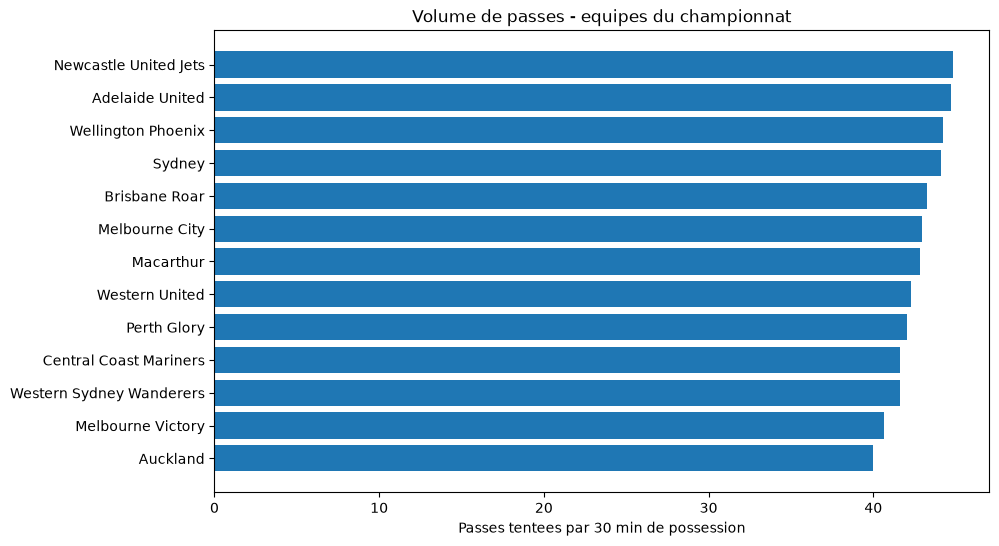

In [131]:
classement = equipes.sort_values('pass_count_attempted_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['pass_count_attempted_p30tip'])
plt.xlabel('Passes tentees par 30 min de possession')
plt.title('Volume de passes - equipes du championnat')


Auckland apparaît en dernière position pour le volume de passes tentées. Cela indique un volume de circulation du ballon plus faible, sans suffire à caractériser à lui seul la vitesse ou la verticalité du jeu.

Passes difficiles

Text(0.5, 1.0, 'Passes difficiles - equipes du championnat')

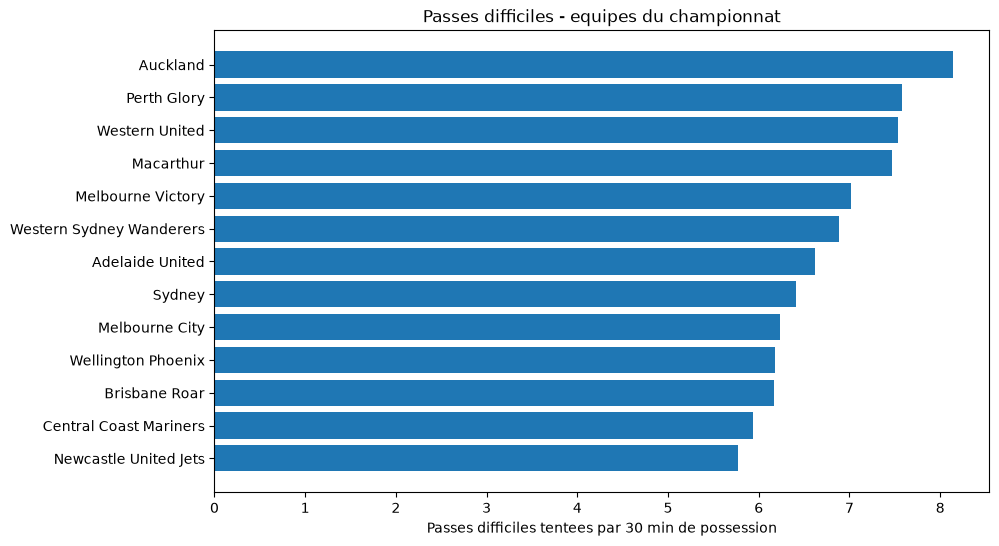

In [132]:
classement = equipes.sort_values('pass_count_difficultpass_attempted_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['pass_count_difficultpass_attempted_p30tip'])
plt.xlabel('Passes difficiles tentees par 30 min de possession')
plt.title('Passes difficiles - equipes du championnat')


Auckland se distingue nettement avec ses passes difficiles tentées par 30 minutes de possession qui représentent le niveau le plus élevé des treize équipes. 

Volume de courses sans ballon

Text(0.5, 1.0, 'Volume de courses sans ballon - equipes du championnat')

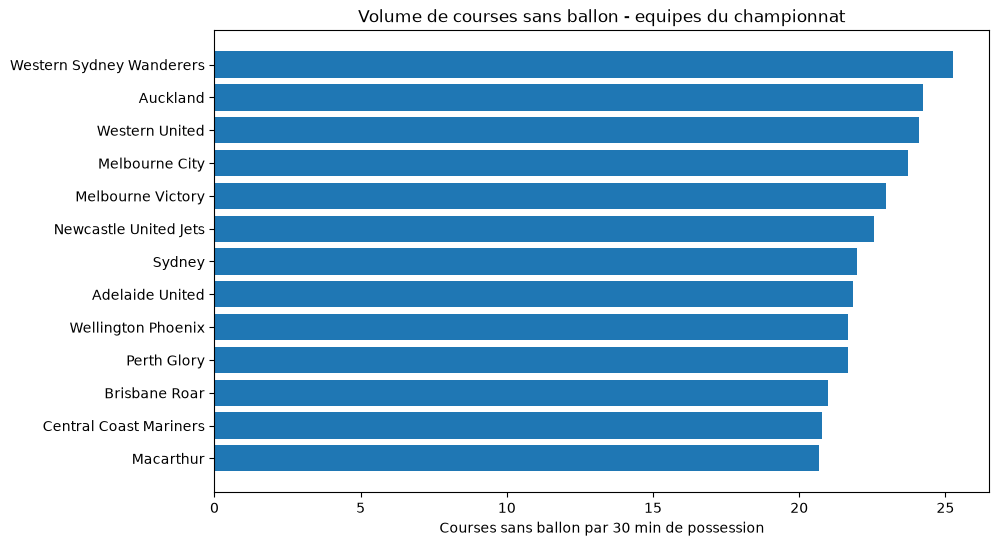

In [133]:
classement = equipes.sort_values('offballrun_count_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['offballrun_count_p30tip'])
plt.xlabel('Courses sans ballon par 30 min de possession')
plt.title('Volume de courses sans ballon - equipes du championnat')


Auckland se situe au deuxième rang en volume de courses sans ballon.

Nuage de points passes et courses

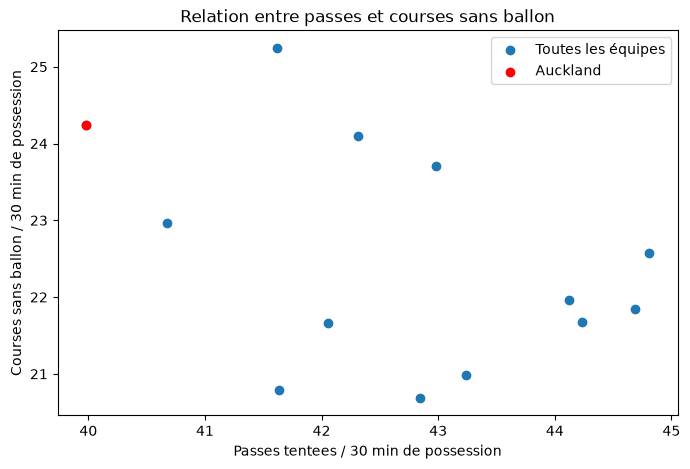

In [134]:
plt.figure(figsize=(8, 5))
plt.scatter(equipes['pass_count_attempted_p30tip'],
            equipes['offballrun_count_p30tip'],
            label='Toutes les équipes')
plt.scatter(auckland['pass_count_attempted_p30tip'],
            auckland['offballrun_count_p30tip'],
            color='red', label='Auckland')
plt.xlabel('Passes tentees / 30 min de possession')
plt.ylabel('Courses sans ballon / 30 min de possession')
plt.title('Relation entre passes et courses sans ballon')
plt.legend()

Auckland se situe dans la partie supérieure du graphique pour le nombre de courses, mais tout à gauche pour les passes. Son profil associe donc un faible volume de passes à une forte fréquence de courses sans ballon. 

Part des passes longues

Text(0.5, 1.0, 'Part des passes longues - equipes du championnat')

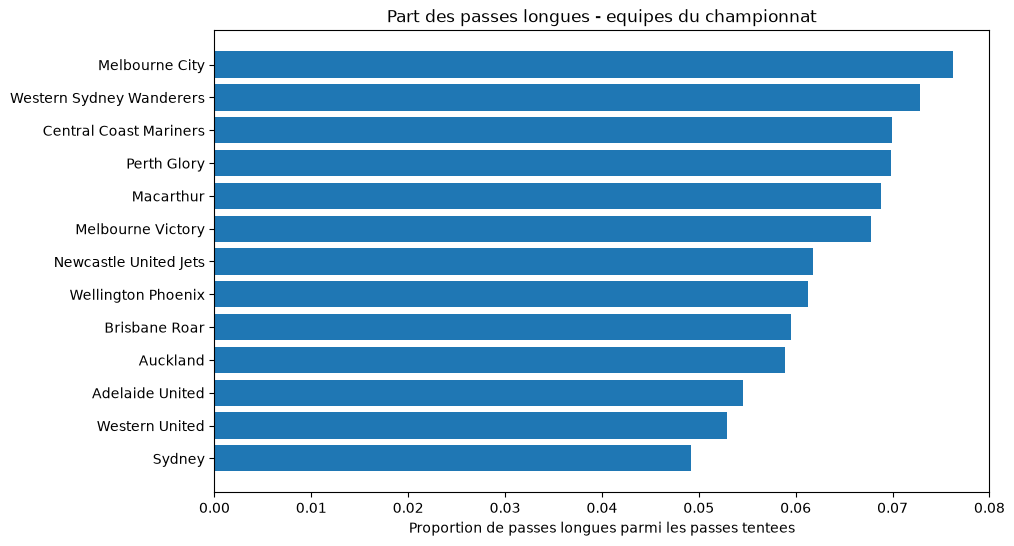

In [135]:
classement = equipes.sort_values('part_passes_longues')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['part_passes_longues'])
plt.xlabel('Proportion de passes longues parmi les passes tentees')
plt.title('Part des passes longues - equipes du championnat')


Malgré son nombre élevé de passes difficiles, Auckland ne se distingue pas par une proportion important de passes longues.

Part des courses dans le dos de la défense

Text(0.5, 1.0, 'Part des courses dans le dos de la defense - equipes du championnat')

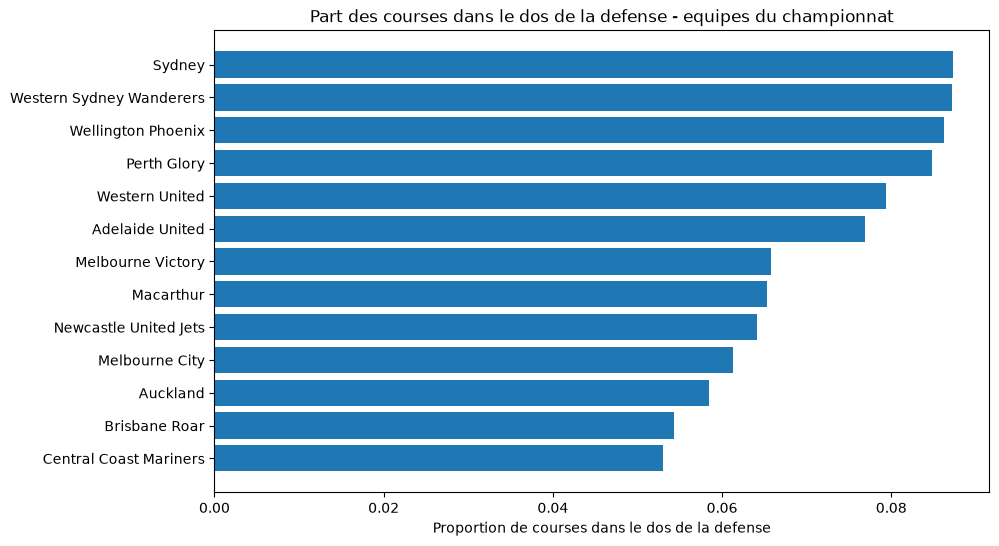

In [136]:
classement = equipes.sort_values('part_courses_dos_defense')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['part_courses_dos_defense'])
plt.xlabel('Proportion de courses dans le dos de la defense')
plt.title('Part des courses dans le dos de la defense - equipes du championnat')


Auckland est une des dernière équipe en termes de proportion de courses dans le dos de la défense, ce qui pourrait traduire un jeu moins direct que ce que l'on pense à cause des passes longues.

## 7. Profil saisonnier d'Auckland FC

Sur la saison 2024-2025, Auckland se caractérise par un faible volume de passes (39,98 par 30 minutes de possession, contre 42,71 pour la ligue) mais par le plus grand nombre de passes difficiles tentées (8,14, contre 6,77). Son taux de passes réussies atteint 80,96 % et la réussite de ses passes cassant une ligne (69,79 %) reste inférieure à la moyenne du championnat (73,20 %).

Le jeu sans ballon constitue une autre caractéristique marquante : Auckland réalise 24,24 courses par 30 minutes de possession, soit le deuxième total de la ligue. Les courses de soutien (4,53) et vers les demi-espaces (0,96) sont particulièrement présentes, tandis que la part des courses dans le dos de la défense demeure relativement limitée (5,85 %).

Limite : ces statistiques collectives sont reconstituées à partir d'agrégats individuels saisonniers et dépendent du filtrage des joueurs et des pondérations retenues.*